# LSTM Data Preprocessing Pipeline: Las Vegas and Phoenix

This notebook prepares the supplied 2016–2023 hourly Las Vegas and Phoenix energy + weather data for the cross city LSTM experiment.

## Key rules

* February 29 is intentionally absent from the final dataset. Leap years transition directly from February 28 to March 1.
* The raw energy files contain leap day rows; the weather files do not.
* The notebook never recreates February 29 when regularizing the hourly timeline.
* The timestamp is authoritative. The weather `hour` field is validated as 1-based.
* Weather variables that are entirely missing or constant are removed based on the supplied data.
* The old universal `energy > 400` rule is not used. Energy outliers are diagnosed using city-specific statistics.
* The target is never interpolated.
* Weather interpolation is conservative: only short internal gaps are filled.
* No lagged, rolling, or historical target features are used.
* Feature definitions are identical between Las Vegas and Phoenix.
* Scalers are fitted only on the source city's training split.
* Cross-city inference uses the source city's fitted scalers.
* LSTM sequences use 24 hours and are generated with memory-efficient `tf.data`.


In [1]:
# 1. Imports and configuration

from pathlib import Path
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
SEQUENCE_LENGTH = 24

BASE_DIR = Path.cwd()

# If the CSVs are in another folder, change BASE_DIR above.
DATA_FILES = {
    "Las Vegas": {
        "weather": BASE_DIR / "data" / "las_vegas_hourly_weather_2016_2023.csv",
        "energy": BASE_DIR / "data" / "las_vegas_hourly_energy.csv",
    },
    "Phoenix": {
        "weather": BASE_DIR / "data" / "phoenix_hourly_weather_2016_2023.csv",
        "energy": BASE_DIR / "data" / "phoenix_hourly_energy.csv",
    },
}

OUTPUT_DIR = BASE_DIR / "processed_lstm"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for city, files in DATA_FILES.items():
    for kind, path in files.items():
        print(f"{city:10s} {kind:8s} -> {path}")
        if not path.exists():
            print("  WARNING: file not found")


Las Vegas  weather  -> d:\Downloads\BTP\model_training\lstm_training_3\las_vegas_hourly_weather_2016_2023.csv
Las Vegas  energy   -> d:\Downloads\BTP\model_training\lstm_training_3\las_vegas_hourly_energy.csv
Phoenix    weather  -> d:\Downloads\BTP\model_training\lstm_training_3\phoenix_hourly_weather_2016_2023.csv
Phoenix    energy   -> d:\Downloads\BTP\model_training\lstm_training_3\phoenix_hourly_energy.csv


## 2. Load and audit the supplied CSVs

The supplied files were inspected before defining the pipeline.

Expected raw sizes from the supplied data:

* Las Vegas energy: 70,128 rows
* Las Vegas weather: 70,080 rows
* Phoenix energy: 70,128 rows
* Phoenix weather: 70,080 rows

The 48-row difference in each city is explained by the two leap years in the eight-year period. The weather files already omit February 29; the energy files contain those 48 leap-day observations and they are removed explicitly.


In [2]:
# 2.1 Load raw data

raw = {}

for city, files in DATA_FILES.items():
    raw[city] = {
        "weather": pd.read_csv(files["weather"]),
        "energy": pd.read_csv(files["energy"]),
    }

for city in raw:
    print(f"\n{'='*75}\n{city}")
    for kind, df in raw[city].items():
        print(f"{kind}: {df.shape}")
        print("Columns:")
        print(list(df.columns))



Las Vegas
weather: (70080, 25)
Columns:
['date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'observation_indicator', 'present_weather', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm', 'timestamp']
energy: (70128, 2)
Columns:
['timestamp', 'hourly_load_mw']

Phoenix
weather: (70080, 25)
Columns:
['date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 't

In [3]:
# 2.2 Detailed raw audit

def raw_audit(city, weather, energy):
    print(f"\n{'#'*80}\n{city} RAW AUDIT\n{'#'*80}")

    for name, df in [("ENERGY", energy), ("WEATHER", weather)]:
        print(f"\n--- {name} ---")

        ts = pd.to_datetime(df["timestamp"], errors="coerce")

        print("Rows:", len(df))
        print("Columns:", len(df.columns))
        print("Timestamp range:", ts.min(), "->", ts.max())
        print("Invalid timestamps:", int(ts.isna().sum()))
        print("Duplicate timestamps:", int(ts.duplicated().sum()))

        feb29 = ((ts.dt.month == 2) & (ts.dt.day == 29)).sum()
        print("February 29 rows:", int(feb29))

        if len(ts.dropna()) > 1:
            sorted_ts = ts.dropna().sort_values()
            diffs = sorted_ts.diff().dropna()
            print("Non-1-hour transitions:", int((diffs != pd.Timedelta(hours=1)).sum()))
            print("Largest gap:", diffs.max())

        if "hourly_load_mw" in df.columns:
            x = pd.to_numeric(df["hourly_load_mw"], errors="coerce")
            print("\nEnergy summary:")
            print(
                x.describe(
                    percentiles=[0.001, 0.01, 0.50, 0.99, 0.999]
                ).round(3)
            )
            print("NaN:", int(x.isna().sum()))
            print("Negative:", int((x < 0).sum()))
            print("Zero:", int((x == 0).sum()))
        else:
            print("\nMissing values:")
            missing = df.isna().sum()
            print(missing[missing > 0].sort_values(ascending=False).to_string())

            print("\nLow-cardinality columns:")
            for c in df.columns:
                nunique = df[c].nunique(dropna=False)
                if nunique <= 3:
                    print(
                        c,
                        "nunique=", nunique,
                        "top=", df[c].value_counts(dropna=False).head(3).to_dict()
                    )

            print("\nNumeric summary:")
            numeric = df.select_dtypes(include=np.number)
            print(
                numeric.describe().T[
                    ["min", "max", "mean", "std"]
                ].round(3).to_string()
            )

for city in raw:
    raw_audit(city, raw[city]["weather"], raw[city]["energy"])



################################################################################
Las Vegas RAW AUDIT
################################################################################

--- ENERGY ---
Rows: 70128
Columns: 2
Timestamp range: 2016-01-01 00:00:00 -> 2023-12-31 23:00:00
Invalid timestamps: 0
Duplicate timestamps: 0
February 29 rows: 48
Non-1-hour transitions: 0
Largest gap: 0 days 01:00:00

Energy summary:
count    70128.000
mean      3235.855
std        807.967
min       2112.989
0.1%      2166.415
1%        2252.548
50%       2976.494
99%       5788.161
99.9%     6330.360
max       6771.353
Name: hourly_load_mw, dtype: float64
NaN: 0
Negative: 0
Zero: 0

--- WEATHER ---
Rows: 70080
Columns: 25
Timestamp range: 2016-01-01 00:00:00 -> 2023-12-31 23:00:00
Invalid timestamps: 0
Duplicate timestamps: 0
February 29 rows: 0
Non-1-hour transitions: 2
Largest gap: 1 days 01:00:00

Missing values:
global_horizontal_radiation_wh_m2     70080
direct_normal_radiation_wh_m2         7008

## 3. Cleaning

### February 29

February 29 is removed from the raw energy data before merging.

### Weather source columns

Based on the supplied files:

* `global_horizontal_radiation_wh_m2` is entirely missing.
* `direct_normal_radiation_wh_m2` is entirely missing.
* `diffuse_horizontal_radiation_wh_m2` is entirely missing.
* `snow_depth_cm` is constant at zero.
* `present_weather` uses the `999999999` source sentinel.
* `observation_indicator` is a source quality indicator, not a physical predictor.

These are excluded from the LSTM feature set.

### Energy

Negative load values are invalid and removed. Zero values are retained only if present because a universal deletion rule should not be assumed without evidence.


In [4]:
# 3.1 Cleaning functions

WEATHER_DROP_COLUMNS = [
    "date",
    "hour",
    "global_horizontal_radiation_wh_m2",
    "direct_normal_radiation_wh_m2",
    "diffuse_horizontal_radiation_wh_m2",
    "snow_depth_cm",
    "present_weather",
    "observation_indicator",
]

def remove_feb29(df):
    ts = pd.to_datetime(df["timestamp"], errors="coerce")
    keep = ~((ts.dt.month == 2) & (ts.dt.day == 29))
    return df.loc[keep].copy()

def clean_energy(df):
    out = df.copy()

    out["timestamp"] = pd.to_datetime(
        out["timestamp"],
        errors="coerce"
    )

    out = out.dropna(subset=["timestamp"])
    out = out.sort_values("timestamp")
    out = out.drop_duplicates(
        subset=["timestamp"],
        keep="first"
    )

    # Critical: energy must match the already leap-day-free weather timeline.
    out = remove_feb29(out)

    out["hourly_load_mw"] = pd.to_numeric(
        out["hourly_load_mw"],
        errors="coerce"
    )

    out = out.dropna(subset=["hourly_load_mw"])
    out = out.loc[out["hourly_load_mw"] >= 0].copy()

    return out.reset_index(drop=True)

def clean_weather(df):
    out = df.copy()

    out["timestamp"] = pd.to_datetime(
        out["timestamp"],
        errors="coerce"
    )

    out = out.dropna(subset=["timestamp"])
    out = out.sort_values("timestamp")
    out = out.drop_duplicates(
        subset=["timestamp"],
        keep="first"
    )

    # Defensive: even though the supplied weather files already omit Feb 29.
    out = remove_feb29(out)

    # Convert the source sentinel to missing before dropping the source field.
    if "present_weather" in out.columns:
        out.loc[
            out["present_weather"] == 999999999,
            "present_weather"
        ] = np.nan

    # Validate the 1-based source hour convention.
    if "hour" in out.columns:
        expected_hour = out["timestamp"].dt.hour + 1
        mismatches = (out["hour"] != expected_hour).sum()
        print("Weather hour/timestamp mismatches:", int(mismatches))

    out = out.drop(
        columns=[c for c in WEATHER_DROP_COLUMNS if c in out.columns],
        errors="ignore"
    )

    return out.reset_index(drop=True)

cleaned = {}

for city in raw:
    cleaned[city] = {
        "energy": clean_energy(raw[city]["energy"]),
        "weather": clean_weather(raw[city]["weather"]),
    }

    print(
        f"{city}:",
        "energy =", cleaned[city]["energy"].shape,
        "weather =", cleaned[city]["weather"].shape
    )


Weather hour/timestamp mismatches: 0
Las Vegas: energy = (70080, 2) weather = (70080, 17)
Weather hour/timestamp mismatches: 0
Phoenix: energy = (70080, 2) weather = (70080, 17)


In [5]:
# 3.2 Verify leap-day removal before merging

for city in cleaned:
    print(f"\n{city}")

    for kind in ["energy", "weather"]:
        ts = cleaned[city][kind]["timestamp"]

        feb29 = (
            (ts.dt.month == 2) &
            (ts.dt.day == 29)
        ).sum()

        print(
            kind,
            "rows =", len(ts),
            "Feb 29 =", int(feb29)
        )

        assert feb29 == 0



Las Vegas
energy rows = 70080 Feb 29 = 0
weather rows = 70080 Feb 29 = 0

Phoenix
energy rows = 70080 Feb 29 = 0
weather rows = 70080 Feb 29 = 0


## 4. Merge energy and weather

The merge is one-to-one on `timestamp`.

After merging, the expected row count is 70,080 per city.

The intentional leap-day removal means that a normal chronological continuity test must **not** demand a 1-hour difference between February 28 23:00 and March 1 00:00. That transition is expected to be a 25-hour timestamp difference because the 24 leap-day hours are intentionally absent.


In [7]:
# 4.1 Merge and validate

merged = {}

for city in cleaned:
    energy = cleaned[city]["energy"]
    weather = cleaned[city]["weather"]

    df = pd.merge(
        energy,
        weather,
        on="timestamp",
        how="inner",
        validate="one_to_one"
    ).sort_values("timestamp").reset_index(drop=True)

    merged[city] = df

    ts = df["timestamp"]

    print(f"\n{city}")
    print("Merged rows:", len(df))
    print("Timestamp:", ts.min(), "->", ts.max())
    print(
        "Feb 29:",
        int(((ts.dt.month == 2) & (ts.dt.day == 29)).sum())
    )
    print("Duplicate timestamps:", int(ts.duplicated().sum()))
    print("Missing cells:", int(df.isna().sum().sum()))

    assert ((ts.dt.month == 2) & (ts.dt.day == 29)).sum() == 0
    assert ts.duplicated().sum() == 0



Las Vegas
Merged rows: 70080
Timestamp: 2016-01-01 00:00:00 -> 2023-12-31 23:00:00
Feb 29: 0
Duplicate timestamps: 0
Missing cells: 0

Phoenix
Merged rows: 70080
Timestamp: 2016-01-01 00:00:00 -> 2023-12-31 23:00:00
Feb 29: 0
Duplicate timestamps: 0
Missing cells: 0


In [9]:
# 4.2 Continuity check that understands the intentional leap-day gap

def continuity_report(df):
    ts = df["timestamp"].sort_values().reset_index(drop=True)

    # Difference between consecutive timestamps
    diffs = ts.diff().dropna().reset_index(drop=True)

    # Normal hourly transition
    normal = (
        diffs == pd.Timedelta(hours=1)
    ).to_numpy()

    # Previous and current timestamps for each transition
    prev = ts.iloc[:-1].reset_index(drop=True)
    curr = ts.iloc[1:].reset_index(drop=True)

    # Expected transition when February 29 has been removed:
    # Feb 28 23:00 -> Mar 1 00:00
    leap_transition = (
        (prev.dt.month == 2) &
        (prev.dt.day == 28) &
        (prev.dt.hour == 23) &
        (curr.dt.month == 3) &
        (curr.dt.day == 1) &
        (curr.dt.hour == 0)
    ).to_numpy()

    # A transition is valid if it is either:
    # 1. A normal 1-hour transition
    # 2. The intentional Feb 28 -> Mar 1 transition
    accepted = normal | leap_transition

    unexpected = ~accepted

    report = {
        "total_transitions": len(diffs),
        "normal_hourly_transitions": int(normal.sum()),
        "expected_leap_transitions": int(leap_transition.sum()),
        "unexpected_transitions": int(unexpected.sum()),
        "largest_gap_hours": float(
            diffs.dt.total_seconds().max() / 3600
        ),
    }

    return report, ts, diffs, unexpected


for city, df in merged.items():

    report, ts, diffs, unexpected = continuity_report(df)

    print(f"\n{city}")
    print(report)

    if unexpected.any():

        bad_idx = np.where(unexpected)[0]

        print("\nUnexpected transitions:")

        for i in bad_idx[:20]:
            print(
                ts.iloc[i],
                "->",
                ts.iloc[i + 1],
                diffs.iloc[i]
            )

    assert report["unexpected_transitions"] == 0


Las Vegas
{'total_transitions': 70079, 'normal_hourly_transitions': 70077, 'expected_leap_transitions': 8, 'unexpected_transitions': 0, 'largest_gap_hours': 25.0}

Phoenix
{'total_transitions': 70079, 'normal_hourly_transitions': 70077, 'expected_leap_transitions': 8, 'unexpected_transitions': 0, 'largest_gap_hours': 25.0}


## 5. Missing weather gaps

A missing timestamp can be introduced if a source has a genuine gap. We therefore detect missing hourly timestamps before interpolation.

The notebook only interpolates **short internal weather gaps**.

Default:

`MAX_WEATHER_GAP_HOURS = 3`

A larger gap is not fabricated. Rows with unresolved weather missingness will later be excluded from sequence windows.

The energy target is never interpolated.


In [10]:
# 5.1 Regularize without recreating February 29

MAX_WEATHER_GAP_HOURS = 3

def regularize_without_feb29(df):
    out = (
        df.copy()
        .sort_values("timestamp")
        .set_index("timestamp")
    )

    full_index = pd.date_range(
        start=out.index.min(),
        end=out.index.max(),
        freq="h"
    )

    # CRITICAL:
    # Remove Feb 29 from the generated index BEFORE reindexing.
    full_index = full_index[
        ~(
            (full_index.month == 2) &
            (full_index.day == 29)
        )
    ]

    out = out.reindex(full_index)
    out.index.name = "timestamp"

    return out.reset_index()

regularized = {}

for city, df in merged.items():
    regularized[city] = regularize_without_feb29(df)

    ts = regularized[city]["timestamp"]

    print(
        city,
        "rows:", len(ts),
        "Feb 29:",
        int(((ts.dt.month == 2) & (ts.dt.day == 29)).sum())
    )

    assert ((ts.dt.month == 2) & (ts.dt.day == 29)).sum() == 0


Las Vegas rows: 70080 Feb 29: 0
Phoenix rows: 70080 Feb 29: 0


In [11]:
# 5.2 Identify missing blocks and conservatively interpolate weather

def missing_blocks(mask):
    mask = pd.Series(mask).astype(bool).reset_index(drop=True)

    blocks = []
    start = None

    for i, value in enumerate(mask):
        if value and start is None:
            start = i
        elif not value and start is not None:
            blocks.append((start, i - 1))
            start = None

    if start is not None:
        blocks.append((start, len(mask) - 1))

    return blocks

def conservative_weather_imputation(df):
    out = df.copy().sort_values("timestamp").reset_index(drop=True)

    target = "hourly_load_mw"
    weather_cols = [
        c for c in out.columns
        if c not in ["timestamp", target]
    ]

    # Keep the target untouched.
    target_missing_before = int(out[target].isna().sum())

    report = {}

    for col in weather_cols:
        missing = out[col].isna()
        blocks = missing_blocks(missing)

        lengths = [end - start + 1 for start, end in blocks]

        report[col] = {
            "missing_before": int(missing.sum()),
            "largest_gap_hours": max(lengths, default=0),
            "short_gap_hours": sum(
                length for length in lengths
                if length <= MAX_WEATHER_GAP_HOURS
            ),
            "large_gap_hours": sum(
                length for length in lengths
                if length > MAX_WEATHER_GAP_HOURS
            ),
        }

        # Interpolate only short internal gaps.
        # limit_area='inside' prevents edge extrapolation.
        if pd.api.types.is_numeric_dtype(out[col]):
            out[col] = out[col].interpolate(
                method="linear",
                limit=MAX_WEATHER_GAP_HOURS,
                limit_area="inside"
            )

    target_missing_after = int(out[target].isna().sum())

    assert target_missing_before == target_missing_after

    return out, pd.DataFrame(report).T

imputed = {}
missing_reports = {}

for city, df in regularized.items():
    imputed[city], missing_reports[city] = (
        conservative_weather_imputation(df)
    )

    print(f"\n{city} missingness report")
    print(missing_reports[city].to_string())

    print(
        "Remaining missing target:",
        int(imputed[city]["hourly_load_mw"].isna().sum())
    )



Las Vegas missingness report
                                                missing_before  largest_gap_hours  short_gap_hours  large_gap_hours
extraterrestrial_horizontal_radiation_wh_m2                  0                  0                0                0
extraterrestrial_direct_normal_radiation_wh_m2               0                  0                0                0
total_sky_cover_tenths                                       0                  0                0                0
opaque_sky_cover_tenths                                      0                  0                0                0
temperature_c                                                0                  0                0                0
dew_point_c                                                  0                  0                0                0
relative_humidity_percent                                    0                  0                0                0
station_pressure_kpa                      

## 6. Energy outlier diagnostics

Las Vegas and Phoenix have different demand scales, so a fixed cutoff such as `400` is not appropriate.

The notebook reports:

* minimum and maximum
* 1st and 99th percentiles
* 0.1th and 99.9th percentiles
* IQR bounds
* number of IQR statistical flags

These flags are diagnostic only. They are not automatically removed because high electricity demand can be a real physical event.


In [12]:
# 6.1 Energy diagnostics

def energy_outlier_report(df):
    x = df["hourly_load_mw"].dropna()

    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return pd.Series({
        "min_mw": x.min(),
        "q001_mw": x.quantile(0.001),
        "q01_mw": x.quantile(0.01),
        "median_mw": x.median(),
        "q99_mw": x.quantile(0.99),
        "q999_mw": x.quantile(0.999),
        "max_mw": x.max(),
        "iqr_lower_mw": lower,
        "iqr_upper_mw": upper,
        "iqr_flag_count": int(((x < lower) | (x > upper)).sum()),
        "iqr_flag_percent": float(((x < lower) | (x > upper)).mean() * 100),
    })

for city, df in imputed.items():
    print(f"\n{city}")
    print(energy_outlier_report(df).round(3))



Las Vegas
min_mw              2112.989
q001_mw             2166.388
q01_mw              2252.718
median_mw           2976.863
q99_mw              5788.313
q999_mw             6330.368
max_mw              6771.353
iqr_lower_mw        1501.079
iqr_upper_mw        4699.007
iqr_flag_count      5673.000
iqr_flag_percent       8.095
dtype: float64

Phoenix
min_mw               3344.201
q001_mw              3463.005
q01_mw               3584.636
median_mw            5092.663
q99_mw              10998.036
q999_mw             12288.411
max_mw              13173.259
iqr_lower_mw         1336.005
iqr_upper_mw         9715.904
iqr_flag_count       3092.000
iqr_flag_percent        4.412
dtype: float64


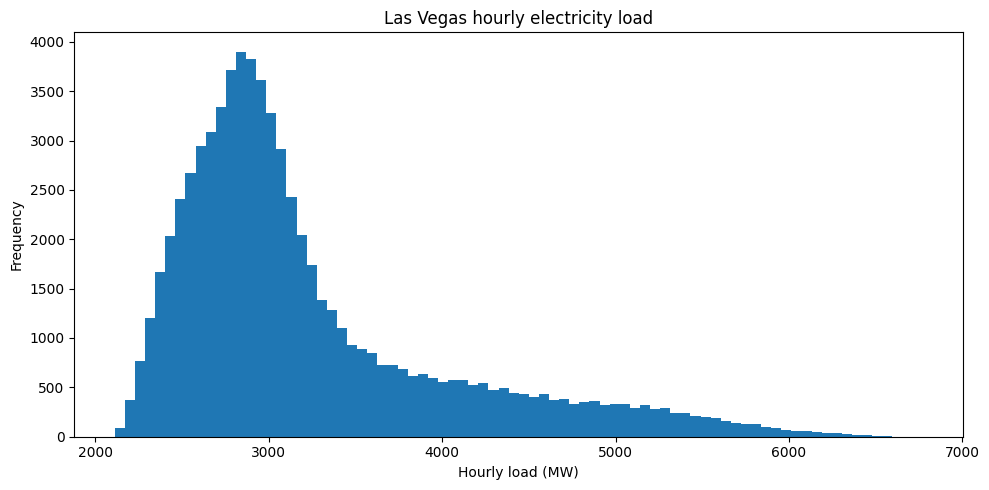

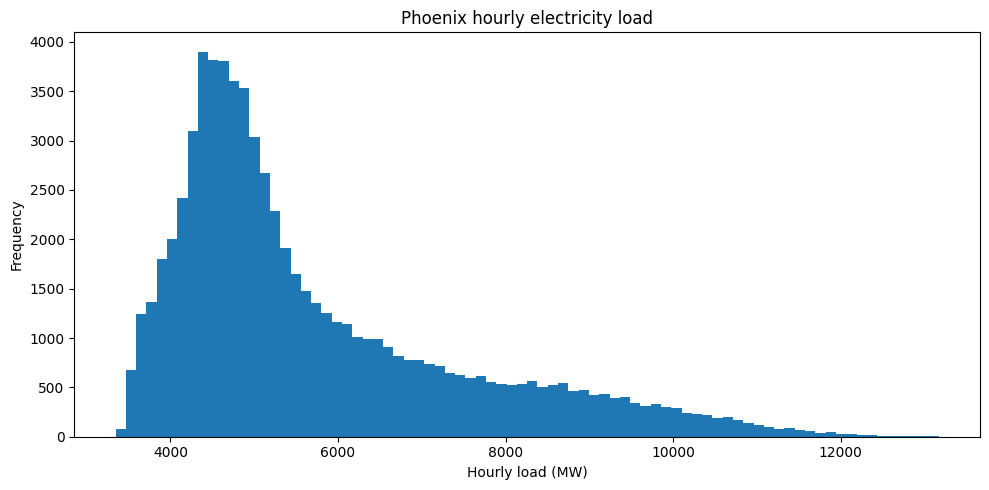

In [13]:
# 6.2 Visualize load distributions

for city, df in imputed.items():
    plt.figure(figsize=(10, 5))
    plt.hist(df["hourly_load_mw"].dropna(), bins=80)
    plt.title(f"{city} hourly electricity load")
    plt.xlabel("Hourly load (MW)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


## 7. Feature engineering

The feature definition is deliberately identical across both cities.

### Raw weather

The supplied weather variables are retained when usable:

* temperature
* dew point
* relative humidity
* station pressure
* wind direction
* wind speed
* visibility
* ceiling height
* precipitable water
* broadband aerosol optical depth
* hourly precipitation

### Calendar/context

* hour
* day of week
* month
* day of year
* weekend
* season

Periodic variables receive sine/cosine encodings.

### Nonlinear weather terms

* temperature squared
* temperature × humidity
* cooling degree hour relative to 18.3°C
* heating degree hour relative to 18.3°C

No energy lag, rolling mean, historical target profile, or other target-derived feature is included.


In [14]:
# 7.1 Feature engineering

def add_features(df):
    out = df.copy().sort_values("timestamp").reset_index(drop=True)
    ts = out["timestamp"]

    # Calendar
    out["hour"] = ts.dt.hour.astype(np.int8)
    out["day_of_week"] = ts.dt.dayofweek.astype(np.int8)
    out["month"] = ts.dt.month.astype(np.int8)
    out["day_of_year"] = ts.dt.dayofyear.astype(np.int16)
    out["is_weekend"] = (ts.dt.dayofweek >= 5).astype(np.int8)

    season_map = {
        12: "winter", 1: "winter", 2: "winter",
        3: "spring", 4: "spring", 5: "spring",
        6: "summer", 7: "summer", 8: "summer",
        9: "autumn", 10: "autumn", 11: "autumn",
    }

    out["season"] = ts.dt.month.map(season_map)

    season_code = {
        "winter": 0,
        "spring": 1,
        "summer": 2,
        "autumn": 3,
    }

    out["season_code"] = (
        out["season"]
        .map(season_code)
        .astype(np.int8)
    )

    # Cyclical calendar features
    out["sin_hour"] = np.sin(
        2 * np.pi * out["hour"] / 24
    )
    out["cos_hour"] = np.cos(
        2 * np.pi * out["hour"] / 24
    )

    out["sin_dow"] = np.sin(
        2 * np.pi * out["day_of_week"] / 7
    )
    out["cos_dow"] = np.cos(
        2 * np.pi * out["day_of_week"] / 7
    )

    out["sin_month"] = np.sin(
        2 * np.pi * (out["month"] - 1) / 12
    )
    out["cos_month"] = np.cos(
        2 * np.pi * (out["month"] - 1) / 12
    )

    # Use 365-day periodicity because Feb 29 is intentionally removed.
    out["sin_doy"] = np.sin(
        2 * np.pi * (out["day_of_year"] - 1) / 365
    )
    out["cos_doy"] = np.cos(
        2 * np.pi * (out["day_of_year"] - 1) / 365
    )

    # Nonlinear weather terms
    BASE_TEMP_C = 18.3

    out["temperature_squared"] = (
        out["temperature_c"] ** 2
    )

    out["temperature_humidity_interaction"] = (
        out["temperature_c"] *
        out["relative_humidity_percent"]
    )

    out["cooling_degree_hour"] = np.maximum(
        out["temperature_c"] - BASE_TEMP_C,
        0
    )

    out["heating_degree_hour"] = np.maximum(
        BASE_TEMP_C - out["temperature_c"],
        0
    )

    return out

featured = {
    city: add_features(df)
    for city, df in imputed.items()
}

for city, df in featured.items():
    print(city, df.shape)


Las Vegas (70080, 37)
Phoenix (70080, 37)


## 8. Final common model feature list

The same columns must exist in both cities.

The `season` string is retained for analysis, but `season_code` is used by the model.

If a weather variable is unavailable or completely missing in either city, it must not silently disappear from only one city's feature matrix. The consistency assertion below will stop the pipeline.


In [15]:
# 8.1 Model features

TARGET = "hourly_load_mw"

MODEL_FEATURES = [
    # Weather
    "temperature_c",
    "dew_point_c",
    "relative_humidity_percent",
    "station_pressure_kpa",
    "wind_direction_deg",
    "wind_speed_ms",
    "horizontal_visibility_km",
    "ceiling_height_m",
    "precipitable_water_mm",
    "broadband_aerosol_optical_depth",
    "hourly_precipitation_cm",

    # Calendar/context
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "season_code",
    "sin_hour",
    "cos_hour",
    "sin_dow",
    "cos_dow",
    "sin_month",
    "cos_month",
    "sin_doy",
    "cos_doy",

    # Nonlinear weather terms
    "temperature_squared",
    "temperature_humidity_interaction",
    "cooling_degree_hour",
    "heating_degree_hour",
]

for city, df in featured.items():
    missing = [c for c in MODEL_FEATURES if c not in df.columns]

    print(city, "missing features:", missing)

    assert not missing

assert len(MODEL_FEATURES) == len(set(MODEL_FEATURES))

print("\nFeature count:", len(MODEL_FEATURES))


Las Vegas missing features: []
Phoenix missing features: []

Feature count: 28


In [16]:
# 8.2 Check feature missingness before scaling

for city, df in featured.items():
    print(f"\n{city}")

    missing = df[MODEL_FEATURES].isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    if len(missing):
        print(missing.to_string())
    else:
        print("No missing model features.")



Las Vegas
No missing model features.

Phoenix
No missing model features.


## 9. Chronological train / validation / test split

The split is chronological:

* 70% training
* 15% validation
* 15% test

No random row split is used.

For cross city evaluation, the source city is used to fit the model and its scalers. The target city is transformed using those source scalers.


In [17]:
# 9.1 Split each city chronologically

def chronological_split(df, train_frac=0.70, val_frac=0.15):
    n = len(df)

    train_end = int(n * train_frac)
    val_end = train_end + int(n * val_frac)

    return (
        df.iloc[:train_end].copy(),
        df.iloc[train_end:val_end].copy(),
        df.iloc[val_end:].copy(),
    )

splits = {}

for city, df in featured.items():
    train, val, test = chronological_split(df)

    splits[city] = {
        "train": train,
        "val": val,
        "test": test,
    }

    print(f"\n{city}")

    for name, part in splits[city].items():
        print(
            f"{name:5s}: {len(part):6d} rows | "
            f"{part['timestamp'].min()} -> {part['timestamp'].max()}"
        )



Las Vegas
train:  49056 rows | 2016-01-01 00:00:00 -> 2021-08-07 23:00:00
val  :  10512 rows | 2021-08-08 00:00:00 -> 2022-10-19 23:00:00
test :  10512 rows | 2022-10-20 00:00:00 -> 2023-12-31 23:00:00

Phoenix
train:  49056 rows | 2016-01-01 00:00:00 -> 2021-08-07 23:00:00
val  :  10512 rows | 2021-08-08 00:00:00 -> 2022-10-19 23:00:00
test :  10512 rows | 2022-10-20 00:00:00 -> 2023-12-31 23:00:00


## 10. Leakage-safe scaling

A StandardScaler is fitted only on the source city's training split.

For example:

```text
Las Vegas train
       ↓
fit LV X scaler + LV y scaler
       ↓
LV validation/test
Phoenix cross-city data
```

The Phoenix distribution is never used to fit the Las Vegas scaler.

The reverse experiment uses the Phoenix training split to fit its own scalers.


In [18]:
# 10.1 Source-city scalers

def fit_source_scalers(train_df):
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train = train_df[MODEL_FEATURES].astype(np.float32)
    y_train = train_df[[TARGET]].astype(np.float32)

    x_scaler.fit(X_train)
    y_scaler.fit(y_train)

    return x_scaler, y_scaler

scalers = {}

for city in splits:
    scalers[city] = {}

    scalers[city]["X"], scalers[city]["y"] = (
        fit_source_scalers(splits[city]["train"])
    )

    print(
        city,
        "X scaler fitted on",
        len(splits[city]["train"]),
        "training rows"
    )


Las Vegas X scaler fitted on 49056 training rows
Phoenix X scaler fitted on 49056 training rows


In [ ]:
# 10.2 Apply a source city's scalers to its local splits

def transform_with_source_scalers(df, x_scaler, y_scaler):
    out = df[["timestamp", TARGET] + MODEL_FEATURES].copy()

    out[MODEL_FEATURES] = x_scaler.transform(
        out[MODEL_FEATURES].astype(np.float32)
    ).astype(np.float32)

    out[TARGET] = y_scaler.transform(
        out[[TARGET]].astype(np.float32)
    ).astype(np.float32).ravel()

    return out

scaled = {}

for city in splits:
    scaled[city] = {}

    for split_name, df in splits[city].items():
        scaled[city][split_name] = transform_with_source_scalers(
            df,
            scalers[city]["X"],
            scalers[city]["y"]
        )

    print(city, "scaled.")


## 11. Cross-city transformations

Two experiments are prepared:

### Experiment A

Las Vegas → Phoenix

* Fit scalers on Las Vegas training data.
* Train the Las Vegas model.
* Transform Phoenix using the Las Vegas scalers.
* Evaluate on Phoenix.

### Experiment B

Phoenix → Las Vegas

The same process is reversed.

The cross-city target remains in the source target scale so model predictions can be inverse transformed correctly.


In [ ]:
# 11.1 Prepare complete target-city data with source-city scaling

cross_city = {}

for source_city, target_city in [
    ("Las Vegas", "Phoenix"),
    ("Phoenix", "Las Vegas"),
]:
    source_x = scalers[source_city]["X"]
    source_y = scalers[source_city]["y"]

    target_df = featured[target_city]

    cross_city[
        f"{source_city}_to_{target_city}"
    ] = transform_with_source_scalers(
        target_df,
        source_x,
        source_y
    )

    print(
        f"{source_city} -> {target_city}:",
        cross_city[f"{source_city}_to_{target_city}"].shape
    )


## 12. Sequence generation

The LSTM uses a 24-hour input window.

For every sequence:

```text
24 consecutive hourly observations
              ↓
           LSTM
              ↓
energy at the final hour
```

Sequences are created separately for train, validation and test splits. This prevents a sequence from accidentally using observations from two different partitions.

For cross-city testing, the target city's complete transformed data can be windowed independently because no target energy history is used as an input feature.


In [ ]:
# 12.1 NumPy sequence builder for sanity checks

def make_sequences_numpy(df, sequence_length=24):
    X = df[MODEL_FEATURES].to_numpy(dtype=np.float32)
    y = df[TARGET].to_numpy(dtype=np.float32)

    n = len(df) - sequence_length + 1

    if n <= 0:
        raise ValueError(
            f"Need at least {sequence_length} rows."
        )

    X_seq = np.empty(
        (n, sequence_length, len(MODEL_FEATURES)),
        dtype=np.float32
    )

    y_seq = np.empty(
        n,
        dtype=np.float32
    )

    for i in range(n):
        end = i + sequence_length
        X_seq[i] = X[i:end]
        y_seq[i] = y[end - 1]

    return X_seq, y_seq

for city in scaled:
    X_check, y_check = make_sequences_numpy(
        scaled[city]["train"].head(200),
        SEQUENCE_LENGTH
    )

    print(
        city,
        "X:", X_check.shape,
        "y:", y_check.shape
    )


In [ ]:
# 12.2 TensorFlow / GPU validation

import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Physical GPUs:", tf.config.list_physical_devices("GPU"))

# Optional memory growth on detected GPUs.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass


In [ ]:
# 12.3 Memory-efficient tf.data sequence pipeline

def make_tf_dataset(
    df,
    batch_size=64,
    sequence_length=24,
    shuffle=False
):
    X = df[MODEL_FEATURES].to_numpy(dtype=np.float32)
    y = df[TARGET].to_numpy(dtype=np.float32)

    # Any remaining missing value means the affected sequence should not
    # be used. Because missingness is already diagnosed above, fail loudly.
    if not np.isfinite(X).all():
        raise ValueError(
            "Feature matrix contains NaN/Inf. "
            "Inspect missing_reports before training."
        )

    if not np.isfinite(y).all():
        raise ValueError(
            "Target contains NaN/Inf."
        )

    ds = tf.data.Dataset.from_tensor_slices((X, y))

    ds = ds.window(
        size=sequence_length,
        shift=1,
        stride=1,
        drop_remainder=True
    )

    ds = ds.flat_map(
        lambda x, y: tf.data.Dataset.zip((
            x.batch(sequence_length, drop_remainder=True),
            y.batch(sequence_length, drop_remainder=True)
        ))
    )

    ds = ds.map(
        lambda x, y: (x, y[-1]),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(df), 10000),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

# Construct local datasets only after the GPU environment has been validated.
tf_datasets = {}

for city in scaled:
    tf_datasets[city] = {
        "train": make_tf_dataset(
            scaled[city]["train"],
            shuffle=True
        ),
        "val": make_tf_dataset(
            scaled[city]["val"],
            shuffle=False
        ),
        "test": make_tf_dataset(
            scaled[city]["test"],
            shuffle=False
        ),
    }

    print(
        city,
        "train batches:",
        tf.data.experimental.cardinality(
            tf_datasets[city]["train"]
        ).numpy()
    )


## 13. Save reproducible preprocessing artifacts

The notebook saves:

* feature-engineered city data
* chronological train / validation / test files
* source-city feature scaler
* source-city target scaler
* cross-city transformed data
* feature metadata
* missingness reports

Large NumPy sequence arrays are deliberately not saved. The `tf.data` pipeline creates them lazily to avoid the RAM issue encountered in the previous LSTM project.


In [ ]:
# 13.1 Save outputs

def city_key(city):
    return city.lower().replace(" ", "_")

for city, df in featured.items():
    key = city_key(city)
    city_dir = OUTPUT_DIR / key
    city_dir.mkdir(parents=True, exist_ok=True)

    df.to_csv(
        city_dir / f"{key}_featured.csv",
        index=False
    )

    for split_name, split_df in splits[city].items():
        split_df.to_csv(
            city_dir / f"{key}_{split_name}.csv",
            index=False
        )

    with open(city_dir / "feature_scaler.pkl", "wb") as f:
        pickle.dump(scalers[city]["X"], f)

    with open(city_dir / "target_scaler.pkl", "wb") as f:
        pickle.dump(scalers[city]["y"], f)

    missing_reports[city].to_csv(
        city_dir / f"{key}_missing_weather_report.csv"
    )

    metadata = {
        "city": city,
        "target": TARGET,
        "model_features": MODEL_FEATURES,
        "sequence_length": SEQUENCE_LENGTH,
        "train_fraction": 0.70,
        "validation_fraction": 0.15,
        "test_fraction": 0.15,
        "feb29_removed": True,
        "max_weather_interpolation_gap_hours": MAX_WEATHER_GAP_HOURS,
        "target_interpolation": False,
        "fixed_energy_outlier_threshold": None,
        "target_derived_features": False,
        "scaler_fit_on": "source city training split only",
    }

    with open(
        city_dir / "preprocessing_metadata.json",
        "w"
    ) as f:
        json.dump(metadata, f, indent=2)

for experiment, df in cross_city.items():
    cross_dir = OUTPUT_DIR / "cross_city"
    cross_dir.mkdir(parents=True, exist_ok=True)

    key = experiment.lower().replace(" ", "_")
    df.to_csv(
        cross_dir / f"{key}.csv",
        index=False
    )

print("Saved preprocessing outputs to:")
print(OUTPUT_DIR.resolve())


# 14. Final validation

This is intentionally stricter than the previous notebook.

The February 29 assertion checks the actual final feature-engineered data. The continuity check explicitly accepts the intentional leap-day transition and rejects any other unexpected gap.

Do not proceed to LSTM training if any assertion in this cell fails.


In [ ]:
# 14.1 Final automated validation

for city, df in featured.items():

    ts = df["timestamp"].sort_values().reset_index(drop=True)

    # 1. No leap-day rows anywhere.
    feb29_count = (
        (ts.dt.month == 2) &
        (ts.dt.day == 29)
    ).sum()

    assert feb29_count == 0, (
        f"{city}: found {feb29_count} February 29 rows"
    )

    # 2. No duplicate timestamps.
    assert ts.duplicated().sum() == 0, (
        f"{city}: duplicate timestamps found"
    )

    # 3. Valid target.
    assert df[TARGET].notna().all(), (
        f"{city}: target contains missing values"
    )

    assert np.isfinite(
        df[TARGET].to_numpy()
    ).all(), (
        f"{city}: target contains non-finite values"
    )

    assert (
        df[TARGET] >= 0
    ).all(), (
        f"{city}: negative energy values found"
    )

    # 4. Feature existence.
    assert all(
        c in df.columns
        for c in MODEL_FEATURES
    ), (
        f"{city}: feature mismatch"
    )

    # 5. Feature completeness.
    assert df[MODEL_FEATURES].notna().all().all(), (
        f"{city}: missing model features remain"
    )

    # 6. Feature finiteness.
    assert np.isfinite(
        df[MODEL_FEATURES].to_numpy(dtype=np.float64)
    ).all(), (
        f"{city}: non-finite model features remain"
    )

    # 7. Continuity with the intentional leap-day gap accepted.
    report, _, _, _ = continuity_report(df)

    assert report["unexpected_transitions"] == 0, (
        f"{city}: unexpected timestamp gap detected"
    )

    print(
        f"{city}: PASS | "
        f"rows={len(df)} | "
        f"Feb29={feb29_count} | "
        f"unexpected gaps={report['unexpected_transitions']}"
    )

print("\nALL FINAL VALIDATION CHECKS PASSED.")


# 15. Cross-city experiment summary

The preprocessing is now ready for the separate LSTM training notebook.

## Las Vegas → Phoenix

```text
Las Vegas training data
        ↓
LV feature scaler
LV target scaler
        ↓
LSTM training
        ↓
Phoenix transformed with LV scalers
        ↓
24-hour sequences
        ↓
Cross-city evaluation
```

## Phoenix → Las Vegas

```text
Phoenix training data
        ↓
PHX feature scaler
PHX target scaler
        ↓
LSTM training
        ↓
Las Vegas transformed with PHX scalers
        ↓
24-hour sequences
        ↓
Cross-city evaluation
```

The two directions should be evaluated independently. Do not fit one global scaler using both cities if the goal is to measure genuine source-to-target transfer.
